In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/gan-monet-image/__results__.html
/kaggle/input/gan-monet-image/__notebook__.ipynb
/kaggle/input/gan-monet-image/__output__.json
/kaggle/input/gan-monet-image/custom.css


In [2]:
import tensorflow as tf

# ENABLE EAGER EXECUTION
tf.config.run_functions_eagerly(True)

print("Eager execution enabled:", tf.executing_eagerly())  # Should be True

# Now run your training

2026-01-25 12:49:50.543344: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1769345390.767284      55 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1769345390.830379      55 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1769345391.354719      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1769345391.354763      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1769345391.354767      55 computation_placer.cc:177] computation placer alr

Eager execution enabled: True


In [3]:
# Set environment variables (Kaggle provides these in notebooks)
# Set KAGGLE_USERNAME and KAGGLE_KEY in your environment (never commit them)
assert 'KAGGLE_KEY' in os.environ, 'Set KAGGLE_USERNAME and KAGGLE_KEY first'

# Then run the command
!kaggle competitions download -c gan-getting-started

 92%|█████████████████████████████████████▌   | 336M/367M [00:02<00:00, 150MB/s]
100%|█████████████████████████████████████████| 367M/367M [00:02<00:00, 162MB/s]


In [4]:
import zipfile

# If you have the zip file
if 'gan-getting-started.zip' in os.listdir('/kaggle/working'):
    print("Found zip file. Extracting...")
    
    with zipfile.ZipFile('/kaggle/working/gan-getting-started.zip', 'r') as zip_ref:
        zip_ref.extractall('/kaggle/working/')
    
    print("Extracted!")

Found zip file. Extracting...
Extracted!


Creating Monet dataset...


I0000 00:00:1769345411.278094      55 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13942 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1769345411.282008      55 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13942 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5
/usr/local/lib/python3.12/dist-packages/tensorflow/python/data/ops/structured_function.py:258: UserWarning: Even though the `tf.config.experimental_run_functions_eagerly` option is set, this option does not apply to tf.data functions. To force eager execution of tf.data functions, please use `tf.data.experimental.enable_debug_mode()`.
  warnings.warn(


Creating Photo dataset...

Testing...
✅ Monet batch shape: (16, 256, 256, 3)
✅ Photo batch shape: (16, 256, 256, 3)


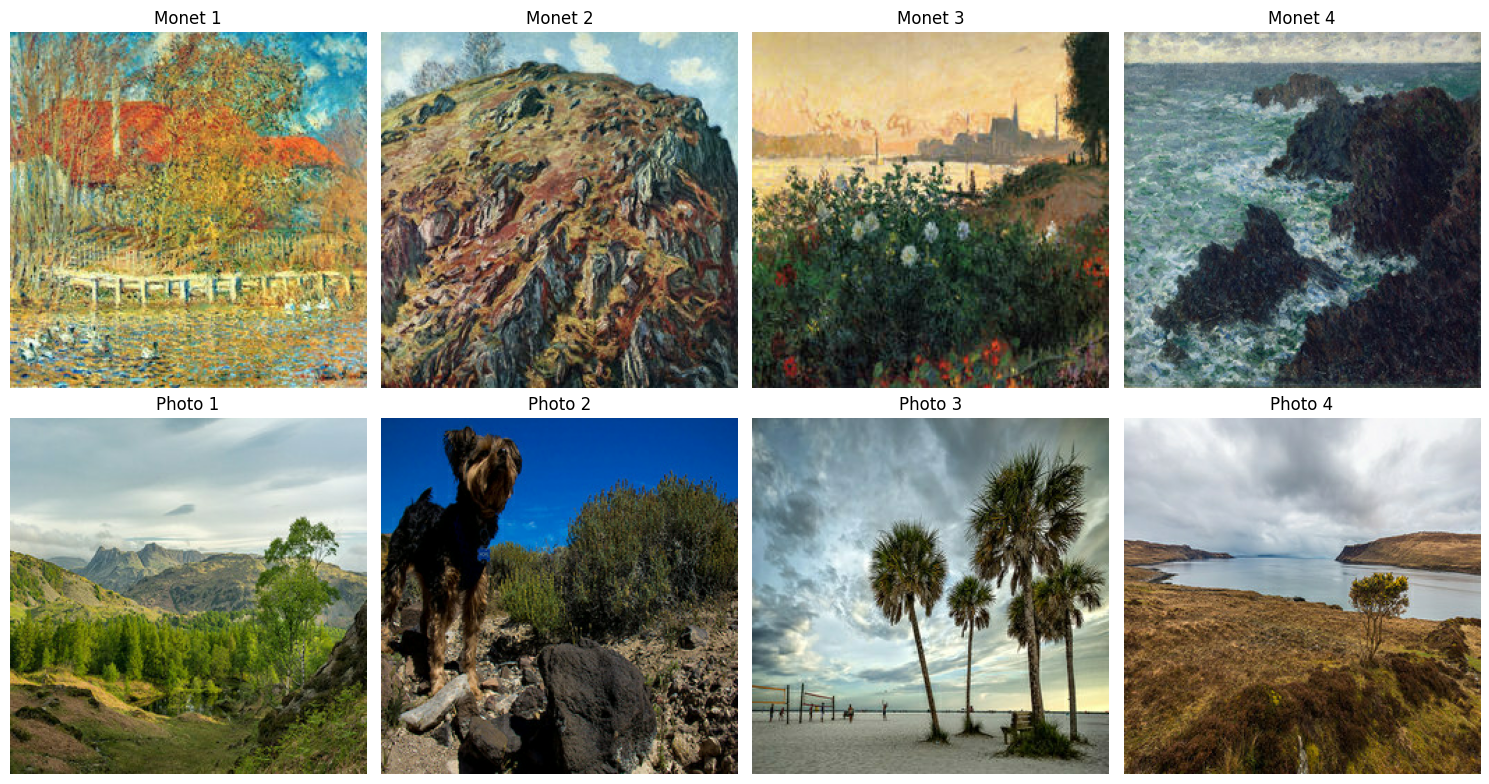


🎉 SUCCESS! Data loaded correctly.


In [5]:
import tensorflow as tf
import matplotlib.pyplot as plt

def parse_image(example):
    """Parser for GAN competition TFRecords"""
    # This competition only has 'image' field
    features = {
        'image': tf.io.FixedLenFeature([], tf.string),
    }
    
    parsed = tf.io.parse_single_example(example, features)
    image = tf.io.decode_jpeg(parsed['image'], channels=3)
    
    # Resize to standard size
    image = tf.image.resize(image, [256, 256])
    
    # Normalize to [-1, 1]
    image = (tf.cast(image, tf.float32) / 127.5) - 1.0
    
    return image

def create_dataset(file_pattern, batch_size=16, shuffle=True):
    """Create TensorFlow dataset from TFRecord pattern"""
    
    # Get files
    files = tf.data.Dataset.list_files(file_pattern, shuffle=shuffle)
    
    # Create dataset
    dataset = files.interleave(
        tf.data.TFRecordDataset,
        cycle_length=tf.data.AUTOTUNE,
        num_parallel_calls=tf.data.AUTOTUNE
    )
    
    # Parse images
    dataset = dataset.map(parse_image, num_parallel_calls=tf.data.AUTOTUNE)
    
    # Shuffle and batch
    if shuffle:
        dataset = dataset.shuffle(1000)
    
    dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    
    return dataset

# Create datasets
print("Creating Monet dataset...")
monet_ds = create_dataset('/kaggle/working/monet_tfrec/*.tfrec')

print("Creating Photo dataset...")
photo_ds = create_dataset('/kaggle/working/photo_tfrec/*.tfrec')

# Test
print("\nTesting...")
for images in monet_ds.take(1):
    print(f"✅ Monet batch shape: {images.shape}")
    
for images in photo_ds.take(1):
    print(f"✅ Photo batch shape: {images.shape}")

# Display samples
fig, axes = plt.subplots(2, 4, figsize=(15, 8))

# Monet samples
for i, img in enumerate(images[:4] for images in monet_ds.take(1)):
    for j in range(4):
        axes[0, j].imshow((img[j] + 1) / 2)
        axes[0, j].set_title(f"Monet {j+1}")
        axes[0, j].axis('off')

# Photo samples  
for i, img in enumerate(images[:4] for images in photo_ds.take(1)):
    for j in range(4):
        axes[1, j].imshow((img[j] + 1) / 2)
        axes[1, j].set_title(f"Photo {j+1}")
        axes[1, j].axis('off')

plt.tight_layout()
plt.show()

print("\n🎉 SUCCESS! Data loaded correctly.")

In [6]:
import tensorflow as tf
from tensorflow.keras import layers

def build_generator():
    """U-Net generator for CycleGAN"""
    
    inputs = layers.Input(shape=[256, 256, 3])
    
    # Downsampling
    # 1
    down1 = layers.Conv2D(64, 4, strides=2, padding='same')(inputs)
    down1 = layers.LeakyReLU()(down1)
    
    # 2
    down2 = layers.Conv2D(128, 4, strides=2, padding='same')(down1)
    down2 = layers.BatchNormalization()(down2)
    down2 = layers.LeakyReLU()(down2)
    
    # 3
    down3 = layers.Conv2D(256, 4, strides=2, padding='same')(down2)
    down3 = layers.BatchNormalization()(down3)
    down3 = layers.LeakyReLU()(down3)
    
    # Bottleneck
    # 4
    down4 = layers.Conv2D(512, 4, strides=2, padding='same')(down3)
    down4 = layers.BatchNormalization()(down4)
    down4 = layers.LeakyReLU()(down4)
    
    # 5
    down5 = layers.Conv2D(512, 4, strides=2, padding='same')(down4)
    down5 = layers.BatchNormalization()(down5)
    down5 = layers.LeakyReLU()(down5)
    
    # 6
    down6 = layers.Conv2D(512, 4, strides=2, padding='same')(down5)
    down6 = layers.BatchNormalization()(down6)
    down6 = layers.LeakyReLU()(down6)
    
    # 7
    down7 = layers.Conv2D(512, 4, strides=2, padding='same')(down6)
    down7 = layers.BatchNormalization()(down7)
    down7 = layers.LeakyReLU()(down7)
    
    # 8
    down8 = layers.Conv2D(512, 4, strides=2, padding='same')(down7)
    down8 = layers.BatchNormalization()(down8)
    down8 = layers.LeakyReLU()(down8)
    
    # Upsampling with skip connections
    # 1
    up1 = layers.Conv2DTranspose(512, 4, strides=2, padding='same')(down8)
    up1 = layers.BatchNormalization()(up1)
    up1 = layers.Dropout(0.5)(up1)
    up1 = layers.Concatenate()([up1, down7])
    up1 = layers.ReLU()(up1)
    
    # 2
    up2 = layers.Conv2DTranspose(512, 4, strides=2, padding='same')(up1)
    up2 = layers.BatchNormalization()(up2)
    up2 = layers.Dropout(0.5)(up2)
    up2 = layers.Concatenate()([up2, down6])
    up2 = layers.ReLU()(up2)
    
    # 3
    up3 = layers.Conv2DTranspose(512, 4, strides=2, padding='same')(up2)
    up3 = layers.BatchNormalization()(up3)
    up3 = layers.Dropout(0.5)(up3)
    up3 = layers.Concatenate()([up3, down5])
    up3 = layers.ReLU()(up3)
    
    # 4
    up4 = layers.Conv2DTranspose(512, 4, strides=2, padding='same')(up3)
    up4 = layers.BatchNormalization()(up4)
    up4 = layers.Concatenate()([up4, down4])
    up4 = layers.ReLU()(up4)
    
    # 5
    up5 = layers.Conv2DTranspose(256, 4, strides=2, padding='same')(up4)
    up5 = layers.BatchNormalization()(up5)
    up5 = layers.Concatenate()([up5, down3])
    up5 = layers.ReLU()(up5)
    
    # 6
    up6 = layers.Conv2DTranspose(128, 4, strides=2, padding='same')(up5)
    up6 = layers.BatchNormalization()(up6)
    up6 = layers.Concatenate()([up6, down2])
    up6 = layers.ReLU()(up6)
    
    # 7
    up7 = layers.Conv2DTranspose(64, 4, strides=2, padding='same')(up6)
    up7 = layers.BatchNormalization()(up7)
    up7 = layers.Concatenate()([up7, down1])
    up7 = layers.ReLU()(up7)
    
    # Output
    output = layers.Conv2DTranspose(3, 4, strides=2, padding='same',
                                    activation='tanh')(up7)
    
    return tf.keras.Model(inputs=inputs, outputs=output)

# Build generators
G = build_generator()  # Photo → Monet
F = build_generator()  # Monet → Photo

print("Generator G (Photo→Monet) built!")
print(f"Parameters: {G.count_params():,}")
print(f"Output shape: {G.output_shape}")

Generator G (Photo→Monet) built!
Parameters: 54,431,363
Output shape: (None, 256, 256, 3)


In [7]:
def build_discriminator():
    """PatchGAN discriminator - outputs patch of predictions, not single value"""
    
    inputs = layers.Input(shape=[256, 256, 3])
    
    # Layer 1: 128×128
    x = layers.Conv2D(64, 4, strides=2, padding='same')(inputs)
    x = layers.LeakyReLU(0.2)(x)
    
    # Layer 2: 64×64
    x = layers.Conv2D(128, 4, strides=2, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(0.2)(x)
    
    # Layer 3: 32×32
    x = layers.Conv2D(256, 4, strides=2, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(0.2)(x)
    
    # Layer 4: 31×31 (due to padding='valid')
    x = layers.Conv2D(512, 4, strides=1, padding='valid')(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(0.2)(x)
    
    # Output: 30×30×1 patch
    output = layers.Conv2D(1, 4, strides=1, padding='valid')(x)
    
    return tf.keras.Model(inputs=inputs, outputs=output)

# Build discriminators
D_M = build_discriminator()  # For Monet images
D_P = build_discriminator()  # For Photo images

print("Discriminator built!")
print(f"Output shape: {D_M.output_shape}")  # Should be (None, 30, 30, 1)
print(f"Parameters: {D_M.count_params():,}")

Discriminator built!
Output shape: (None, 26, 26, 1)
Parameters: 2,768,321


In [8]:
import tensorflow as tf
from tensorflow.keras import layers

# Step 3: Create Loss Functions and Optimizers

# Loss weights (from CycleGAN paper)
LAMBDA_CYCLE = 10.0  # Cycle consistency loss weight
LAMBDA_IDENTITY = 0.5  # Identity loss weight (optional)

# 1. Adversarial loss (standard GAN loss)
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)

def discriminator_loss(real, generated):
    """
    Discriminator wants: real images = 1, fake images = 0
    real: discriminator predictions on real images
    generated: discriminator predictions on fake images
    """
    real_loss = cross_entropy(tf.ones_like(real), real)
    fake_loss = cross_entropy(tf.zeros_like(generated), generated)
    return real_loss + fake_loss

def generator_loss(generated):
    """
    Generator wants discriminator to think fakes are real (output 1)
    generated: discriminator predictions on fake images
    """
    return cross_entropy(tf.ones_like(generated), generated)

def calc_cycle_loss(real_image, cycled_image):
    """Cycle consistency loss (L1 distance)"""
    return tf.reduce_mean(tf.abs(real_image - cycled_image))

def identity_loss(real_image, same_image):
    """Identity loss: generator shouldn't change images already in target domain"""
    return tf.reduce_mean(tf.abs(real_image - same_image)) * LAMBDA_IDENTITY

# Step 4: Create Optimizers
# Different learning rates for generators and discriminators
generator_optimizer = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)
discriminator_M_optimizer = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)
discriminator_P_optimizer = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)

print("✅ Loss functions and optimizers created!")
print(f"Generator optimizer: {generator_optimizer}")
print(f"Discriminator M optimizer: {discriminator_M_optimizer}")
print(f"Discriminator P optimizer: {discriminator_P_optimizer}")

✅ Loss functions and optimizers created!
Generator optimizer: <keras.src.optimizers.adam.Adam object at 0x7e20468c96a0>
Discriminator M optimizer: <keras.src.optimizers.adam.Adam object at 0x7e20468d6780>
Discriminator P optimizer: <keras.src.optimizers.adam.Adam object at 0x7e200c9ebe00>


In [9]:
# Step 5: Setup Checkpoints (to save model during training)
import os

checkpoint_dir = './training_checkpoints'
checkpoint_prefix = os.path.join(checkpoint_dir, "ckpt")

# What to save
checkpoint = tf.train.Checkpoint(
    generator_G=G,          # Photo → Monet
    generator_F=F,          # Monet → Photo
    discriminator_M=D_M,    # Monet discriminator  
    discriminator_P=D_P,    # Photo discriminator
    generator_optimizer=generator_optimizer,
    discriminator_M_optimizer=discriminator_M_optimizer,  # Separate!
    discriminator_P_optimizer=discriminator_P_optimizer   # Separate!
)

# Create checkpoint directory
if not os.path.exists(checkpoint_dir):
    os.makedirs(checkpoint_dir)
    print(f"Created checkpoint directory: {checkpoint_dir}")

print("✅ Checkpoint setup complete!")

Created checkpoint directory: ./training_checkpoints
✅ Checkpoint setup complete!


In [10]:
# Step 6: Create the training step function
@tf.function  # Compile to graph for faster execution
def train_step(real_monet, real_photo):
    """
    Single training step for CycleGAN
    real_monet: batch of real Monet paintings
    real_photo: batch of real photos
    """
    
    # Persistent gradient tape for multiple gradient calculations
    with tf.GradientTape(persistent=True) as tape:
        # GENERATE FAKE IMAGES
        fake_monet = G(real_photo, training=True)   # Photo → Monet
        fake_photo = F(real_monet, training=True)   # Monet → Photo
        
        # CYCLE RECONSTRUCTIONS
        cycled_photo = F(fake_monet, training=True)  # Photo → Monet → Photo
        cycled_monet = G(fake_photo, training=True)  # Monet → Photo → Monet
        
        # IDENTITY MAPPINGS (optional but helpful)
        same_monet = G(real_monet, training=True)    # Monet → Monet (shouldn't change)
        same_photo = F(real_photo, training=True)    # Photo → Photo (shouldn't change)
        
        # DISCRIMINATOR PREDICTIONS
        disc_real_monet = D_M(real_monet, training=True)
        disc_fake_monet = D_M(fake_monet, training=True)
        
        disc_real_photo = D_P(real_photo, training=True)
        disc_fake_photo = D_P(fake_photo, training=True)
        
        # ========== CALCULATE LOSSES ==========
        
        # 1. Generator adversarial losses
        gen_G_loss = generator_loss(disc_fake_monet)  # G tries to fool D_M
        gen_F_loss = generator_loss(disc_fake_photo)  # F tries to fool D_P
        
        # 2. Cycle consistency losses
        total_cycle_loss = calc_cycle_loss(real_photo, cycled_photo) + \
                          calc_cycle_loss(real_monet, cycled_monet)
        
        # 3. Identity losses (optional)
        total_identity_loss = identity_loss(real_monet, same_monet) + \
                             identity_loss(real_photo, same_photo)
        
        # TOTAL GENERATOR LOSS (weighted sum)
        total_gen_loss = gen_G_loss + gen_F_loss + \
                        (total_cycle_loss * LAMBDA_CYCLE) + \
                        total_identity_loss
        
        # 4. Discriminator losses
        disc_M_loss = discriminator_loss(disc_real_monet, disc_fake_monet)
        disc_P_loss = discriminator_loss(disc_real_photo, disc_fake_photo)
        
        total_disc_loss = disc_M_loss + disc_P_loss
    
    # ========== CALCULATE GRADIENTS ==========
    
    # Generator gradients (G and F)
    gen_gradients = tape.gradient(total_gen_loss, 
                                 G.trainable_variables + F.trainable_variables)
    
    # Discriminator gradients (D_M and D_P)
    disc_M_gradients = tape.gradient(disc_M_loss, D_M.trainable_variables)
    disc_P_gradients = tape.gradient(disc_P_loss, D_P.trainable_variables)
    
    # ========== APPLY GRADIENTS ==========
    
    # Update generators
    generator_optimizer.apply_gradients(
        zip(gen_gradients, G.trainable_variables + F.trainable_variables)
    )
    
    # Update discriminators
    discriminator_M_optimizer.apply_gradients(zip(disc_M_gradients, D_M.trainable_variables))
    discriminator_P_optimizer.apply_gradients(zip(disc_P_gradients, D_P.trainable_variables))
    
    return total_gen_loss, disc_M_loss, disc_P_loss

print("✅ Training step function created!")

✅ Training step function created!


In [11]:
# Step 7: Training Loop
import time
import matplotlib.pyplot as plt

def generate_images(model, test_input):
    """Generate and display images for monitoring"""
    prediction = model(test_input, training=False)
    
    plt.figure(figsize=(12, 12))
    
    display_list = [test_input[0], prediction[0]]
    title = ['Input Image', 'Predicted Image']
    
    for i in range(2):
        plt.subplot(1, 2, i+1)
        plt.title(title[i])
        # Convert from [-1, 1] to [0, 1] for display
        plt.imshow(display_list[i] * 0.5 + 0.5)
        plt.axis('off')
    plt.show()

def fit(train_monet, train_photo, epochs):
    """Main training function"""
    
    # Take one sample for monitoring
    sample_monet = next(iter(train_monet.take(1)))
    sample_photo = next(iter(train_photo.take(1)))
    
    print(f"Starting training for {epochs} epochs...")
    
    for epoch in range(epochs):
        start = time.time()
        
        gen_losses = []
        disc_M_losses = []
        disc_P_losses = []
        
        # Train on batches
        for n, (monet_batch, photo_batch) in enumerate(zip(train_monet, train_photo)):
            gen_loss, d_M_loss, d_P_loss = train_step(monet_batch, photo_batch)
            
            gen_losses.append(gen_loss)
            disc_M_losses.append(d_M_loss)
            disc_P_losses.append(d_P_loss)
            
            if n % 2 == 0:
                print(f"  Batch {n}: G_loss={gen_loss:.4f}, D_M={d_M_loss:.4f}, D_P={d_P_loss:.4f}")
        
        # Calculate epoch averages
        avg_gen_loss = tf.reduce_mean(gen_losses)
        avg_disc_M_loss = tf.reduce_mean(disc_M_losses)
        avg_disc_P_loss = tf.reduce_mean(disc_P_losses)
        
        # Display progress
        print(f"Epoch {epoch+1}/{epochs}")
        print(f"  Time: {time.time()-start:.2f}s")
        print(f"  Gen Loss: {avg_gen_loss:.4f}")
        print(f"  Disc M Loss: {avg_disc_M_loss:.4f}")
        print(f"  Disc P Loss: {avg_disc_P_loss:.4f}")
        
        # Generate sample images every few epochs
        if (epoch + 1) % 5 == 0:
            print("Generating sample images...")
            generate_images(G, sample_photo)  # Photo → Monet
        
        # Save checkpoint every 10 epochs
        if (epoch + 1) % 10 == 0:
            checkpoint.save(file_prefix=checkpoint_prefix)
            print(f"  Checkpoint saved!")
    
    # Final checkpoint
    checkpoint.save(file_prefix=checkpoint_prefix)
    print(f"Training complete! Final checkpoint saved.")

print("✅ Training loop ready!")

✅ Training loop ready!


Creating datasets...
Monet batches: 19
Photo batches: 440

🚀 Starting training for 8 epochs...
This might take a while...
Starting training for 8 epochs...


I0000 00:00:1769345424.843633      55 cuda_dnn.cc:529] Loaded cuDNN version 91002


  Batch 0: G_loss=11.4204, D_M=1.5865, D_P=1.5974
  Batch 2: G_loss=10.5334, D_M=1.9037, D_P=2.0539
  Batch 4: G_loss=9.2087, D_M=1.6695, D_P=1.6324
  Batch 6: G_loss=8.2713, D_M=1.5662, D_P=1.4792
  Batch 8: G_loss=7.4301, D_M=1.4123, D_P=1.3285
  Batch 10: G_loss=7.1794, D_M=1.3049, D_P=1.2847
  Batch 12: G_loss=6.2426, D_M=1.4061, D_P=1.2943
  Batch 14: G_loss=7.2901, D_M=1.5718, D_P=1.4760
  Batch 16: G_loss=6.0977, D_M=1.3993, D_P=1.4130
  Batch 18: G_loss=5.9400, D_M=1.3979, D_P=1.3725
Epoch 1/8
  Time: 78.48s
  Gen Loss: 7.9251
  Disc M Loss: 1.5916
  Disc P Loss: 1.5327
  Batch 0: G_loss=6.0465, D_M=1.4402, D_P=1.5052
  Batch 2: G_loss=6.0209, D_M=1.8488, D_P=2.0287
  Batch 4: G_loss=5.5627, D_M=1.5739, D_P=1.6648
  Batch 6: G_loss=5.5751, D_M=1.5892, D_P=1.4311
  Batch 8: G_loss=5.1935, D_M=1.4496, D_P=1.4364
  Batch 10: G_loss=5.0142, D_M=1.4139, D_P=1.3592
  Batch 12: G_loss=4.5031, D_M=1.3992, D_P=1.4055
  Batch 14: G_loss=5.1492, D_M=1.3556, D_P=1.3182
  Batch 16: G_loss=5

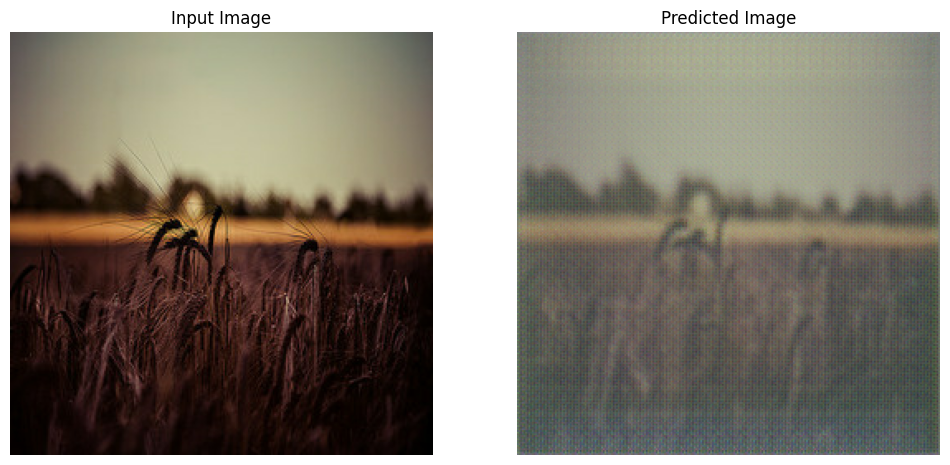

  Batch 0: G_loss=3.9835, D_M=1.3990, D_P=1.3420
  Batch 2: G_loss=4.1590, D_M=1.3631, D_P=1.3888
  Batch 4: G_loss=4.1757, D_M=1.3732, D_P=1.4201
  Batch 6: G_loss=3.9574, D_M=1.3411, D_P=1.3576
  Batch 8: G_loss=4.3562, D_M=1.3545, D_P=1.3572
  Batch 10: G_loss=4.0301, D_M=1.4287, D_P=1.3826
  Batch 12: G_loss=4.3471, D_M=1.4933, D_P=1.4269
  Batch 14: G_loss=4.0960, D_M=1.3549, D_P=1.3770
  Batch 16: G_loss=4.0614, D_M=1.3535, D_P=1.3899
  Batch 18: G_loss=4.2392, D_M=1.3302, D_P=1.3651
Epoch 6/8
  Time: 69.83s
  Gen Loss: 4.1671
  Disc M Loss: 1.3811
  Disc P Loss: 1.3871
  Batch 0: G_loss=4.0455, D_M=1.3396, D_P=1.3745
  Batch 2: G_loss=4.4312, D_M=1.3337, D_P=1.3666
  Batch 4: G_loss=4.2124, D_M=1.3329, D_P=1.3872
  Batch 6: G_loss=3.7685, D_M=1.3519, D_P=1.3751
  Batch 8: G_loss=5.1405, D_M=1.4307, D_P=1.3398
  Batch 10: G_loss=3.8252, D_M=1.3721, D_P=1.4210
  Batch 12: G_loss=4.1242, D_M=1.4091, D_P=1.4380
  Batch 14: G_loss=3.7762, D_M=1.3797, D_P=1.3293
  Batch 16: G_loss=3.8

In [12]:
# Step 8: Prepare datasets and start training

# Create datasets (use smaller batch size to save memory)
BATCH_SIZE = 4  # Start small, increase if you have GPU memory

# Assuming you already have monet_ds and photo_ds from earlier
# If not, create them:
def create_dataset(file_pattern, batch_size):
    def parse_tfrecord(example):
        features = {'image': tf.io.FixedLenFeature([], tf.string)}
        parsed = tf.io.parse_single_example(example, features)
        image = tf.io.decode_jpeg(parsed['image'], channels=3)
        image = tf.image.resize(image, [256, 256])
        image = (tf.cast(image, tf.float32) / 127.5) - 1.0
        return image
    
    files = tf.data.Dataset.list_files(file_pattern)
    dataset = files.interleave(tf.data.TFRecordDataset)
    dataset = dataset.map(parse_tfrecord, num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.shuffle(1000).batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return dataset

print("Creating datasets...")
#train_monet = create_dataset('/kaggle/input/gan-getting-started/monet_tfrec/*.tfrec', BATCH_SIZE)
#train_photo = create_dataset('/kaggle/input/gan-getting-started/photo_tfrec/*.tfrec', BATCH_SIZE)

train_monet = monet_ds
train_photo = photo_ds

print(f"Monet batches: {len(list(train_monet))}")
print(f"Photo batches: {len(list(train_photo))}")

# Start training with just 2 epochs to test
EPOCHS = 8  # Start small!
print(f"\n🚀 Starting training for {EPOCHS} epochs...")
print("This might take a while...")

# Uncomment to start training:
fit(train_monet, train_photo, EPOCHS)

print("\n⚠️  Uncomment the line above to start training!")
print("Recommended: Start with 2 epochs to see if it works, then train more.")

In [13]:
G.save('monet_generator.h5')  # ✅ Submit this!

In [14]:
G.save('monet_generator.keras')  # ✅ Submit this!

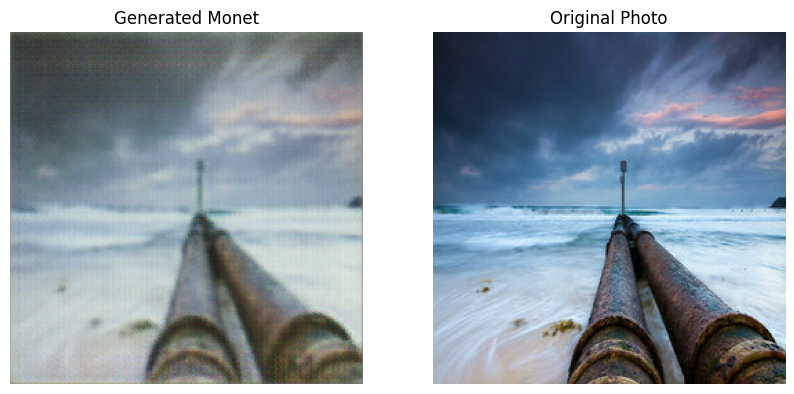

In [15]:
# Test your trained generator
test_photo = next(iter(photo_ds.take(10)))
generated_monet = G(test_photo, training=False)

# Display
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[1].imshow((test_photo[0] + 1) / 2)
axes[1].set_title("Original Photo")
axes[1].axis('off')

axes[0].imshow((generated_monet[0] + 1) / 2)
axes[0].set_title("Generated Monet")
axes[0].axis('off')
plt.show()

In [22]:
import tensorflow as tf
import numpy as np
import zipfile
import os
from PIL import Image
import tempfile

print("TensorFlow version:", tf.__version__)

# ====================== 1. LOAD TRAINED GENERATOR ======================
def load_generator(model_path='monet_generator.h5'):
    """Load your trained Photo→Monet generator"""
    print(f"Loading generator from {model_path}...")
    
    # Load the model
    G = tf.keras.models.load_model(model_path, compile=False)
    
    # Test it works
    dummy_input = tf.random.normal([1, 256, 256, 3])
    output = G(dummy_input, training=False)
    print(f"✅ Generator loaded successfully!")
    print(f"   Input shape: {dummy_input.shape}")
    print(f"   Output shape: {output.shape}")
    
    return G

# ====================== 2. LOAD TEST IMAGES ======================
def load_test_images(test_pattern):
    """Load test photos (Kaggle provides these)"""
    print(f"Loading test images from {test_pattern}...")
    
    def parse_tfrecord(example):
        """Parse TFRecord for test images - NO ID FIELD!"""
        features = {
            'image': tf.io.FixedLenFeature([], tf.string),  # ONLY IMAGE!
        }
        parsed = tf.io.parse_single_example(example, features)
        image = tf.io.decode_jpeg(parsed['image'], channels=3)
        image = tf.image.resize(image, [256, 256])
        image = (tf.cast(image, tf.float32) / 127.5) - 1.0  # [-1, 1]
        return image
    
    # Load all test files
    test_files = tf.io.gfile.glob(test_pattern)
    
    # If no test files found, fallback to training data for local testing
    if not test_files:
        print("⚠️  No test files found at given pattern")
        print("   Using training photos as dummy test data...")
        test_pattern = '/kaggle/working/photo_tfrec/*.tfrec'
        test_files = tf.io.gfile.glob(test_pattern)
    
    print(f"Found {len(test_files)} TFRecord files")
    
    dataset = tf.data.TFRecordDataset(test_files)
    dataset = dataset.map(parse_tfrecord, num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.batch(1)  # Process one at a time
    
    return dataset

# ====================== 3. GENERATE MONET IMAGES ======================
def generate_monet_images(G, test_dataset, num_images=10000):
    """Convert test photos to Monet style"""
    print(f"Generating Monet images...")
    
    generated_images = []
    
    for i, photo in enumerate(test_dataset):
        if i >= num_images:
            break
            
        # Generate Monet version
        monet = G(photo, training=False)
        
        # Convert from [-1, 1] to [0, 255] uint8
        img_array = ((monet[0] + 1) * 127.5).numpy()
        img_array = np.clip(img_array, 0, 255).astype(np.uint8)
        
        # Ensure correct size
        if img_array.shape[:2] != (256, 256):
            img_array = tf.image.resize(img_array, [256, 256]).numpy()
        
        generated_images.append(img_array)
        
        # Progress indicator
        if (i + 1) % 100 == 0:
            print(f"  Generated {i + 1} images...")
    
    print(f"✅ Generated {len(generated_images)} Monet images")
    return generated_images

# ====================== 4. CREATE SUBMISSION ZIP ======================
def create_submission_zip(images, output_path='images.zip'):
    """Create the submission zip file"""
    print(f"Creating submission zip: {output_path}...")
    
    # Create temporary directory
    temp_dir = tempfile.mkdtemp()
    
    # Save each image as JPG
    for i, img in enumerate(images):
        # Convert numpy array to PIL Image
        pil_img = Image.fromarray(img)
        
        # Save as JPG
        img_path = os.path.join(temp_dir, f'{i}.jpg')
        pil_img.save(img_path, 'JPEG', quality=95)
    
    # Create zip file
    with zipfile.ZipFile(output_path, 'w', zipfile.ZIP_DEFLATED) as zipf:
        for i in range(len(images)):
            img_path = os.path.join(temp_dir, f'{i}.jpg')
            zipf.write(img_path, f'{i}.jpg')
    
    # Cleanup
    for file in os.listdir(temp_dir):
        os.remove(os.path.join(temp_dir, file))
    os.rmdir(temp_dir)
    
    print(f"✅ Created {output_path} with {len(images)} images")
    print(f"   File size: {os.path.getsize(output_path) / (1024*1024):.1f} MB")

# ====================== 5. MAIN INFERENCE FUNCTION ======================
def main():
    """Complete inference pipeline for submission"""
    
    print("="*60)
    print("GAN GETTING STARTED - INFERENCE FOR SUBMISSION")
    print("="*60)
    
    # Paths (Kaggle competition paths)
    GENERATOR_PATH = '/kaggle/working/monet_generator.h5'  # Your saved model
    TEST_DATA_PATTERN = '/kaggle/input/gan-getting-started/test_tfrec/*.tfrec'
    OUTPUT_ZIP = '/kaggle/working/images.zip'  # Must be this exact name!
    
    # Step 1: Load generator
    G = load_generator(GENERATOR_PATH)
    
    # Step 2: Load test images
    test_dataset = load_test_images(TEST_DATA_PATTERN)
    
    # Step 3: Generate Monet images
    generated_images = generate_monet_images(G, test_dataset, num_images=10000)
    
    # Step 4: Create submission zip
    create_submission_zip(generated_images, OUTPUT_ZIP)
    
    # Step 5: Verify submission
    print("\n" + "="*60)
    print("SUBMISSION VERIFICATION")
    print("="*60)
    
    # Check zip file
    if os.path.exists(OUTPUT_ZIP):
        with zipfile.ZipFile(OUTPUT_ZIP, 'r') as zipf:
            file_count = len(zipf.namelist())
            print(f"✅ Submission zip contains {file_count} images")
            
            # Check first image
            with zipf.open('0.jpg') as f:
                img = Image.open(f)
                print(f"✅ First image: {img.size} pixels, {img.mode} mode")
    
    print(f"\n🎉 SUBMISSION READY!")
    print(f"Upload this file to Kaggle: {OUTPUT_ZIP}")

# ====================== RUN INFERENCE ======================
if __name__ == '__main__':
    main()

TensorFlow version: 2.19.0
GAN GETTING STARTED - INFERENCE FOR SUBMISSION
Loading generator from /kaggle/working/monet_generator.h5...
✅ Generator loaded successfully!
   Input shape: (1, 256, 256, 3)
   Output shape: (1, 256, 256, 3)
Loading test images from /kaggle/input/gan-getting-started/test_tfrec/*.tfrec...
⚠️  No test files found at given pattern
   Using training photos as dummy test data...
Found 20 TFRecord files
Generating Monet images...
  Generated 100 images...
  Generated 200 images...
  Generated 300 images...
  Generated 400 images...
  Generated 500 images...
  Generated 600 images...
  Generated 700 images...
  Generated 800 images...
  Generated 900 images...
  Generated 1000 images...
  Generated 1100 images...
  Generated 1200 images...
  Generated 1300 images...
  Generated 1400 images...
  Generated 1500 images...
  Generated 1600 images...
  Generated 1700 images...
  Generated 1800 images...
  Generated 1900 images...
  Generated 2000 images...
  Generated 21